In [35]:
%% Homework 1, SIOC 221a, 8 Oct 2026, Ely Dawson

In [81]:
function pier=Get2021PierData(date_start,date_end,file)
% a modification of the class code given to us. Updated for current version
% of MatLAB and changed for my own preferences. I didn't change much. 
% 
% Alterations:
%   - changed vars names
%   - updated outdated code structs (datenum to datetime)
%   - specified 2021 data rather than 2020
%   - changed the dnum var to a cleaner form
% 
% Version 1.2, 8 Oct 2026, Ely J. Dawson
%

if nargin < 3 || isempty(file)
    file = FindPierFile();
end

time = ncread(file,'time');
temperature = ncread(file,'temperature');
pressure = ncread(file,'pressure');
dnum = datetime(time,"ConvertFrom","posixtime");

if nargin < 1
    i1 = 1:numel(dnum); %no dates given: return the whole record
else
    i1 = find(dnum > date_start & dnum < date_end);
end

pier.dnum = dnum(i1);
pier.temperature = temperature(i1);
pier.pressure = pressure(i1);
pier.readme = '2021 Pier data, SIO221a, function Get2021PierData.m';
end

function file = FindPierFile()
%Locate data/scripps_pier-2021.nc without hard-coding anybody's home
%directory. This function knows where IT lives, so the data must be its
%sibling: mha_code/ and data/ are both inside the class repo.
here = fileparts(mfilename('fullpath')); %.../SIO221a_Github_code_2026/mha_code
repo = fileparts(here); %.../SIO221a_Github_code_2026
sentinel = fullfile('data','scripps_pier-2021.nc');
candidates = {fullfile(repo,sentinel), ...
fullfile(getenv('SIO221A_ROOT'),sentinel)};
    for k = 1:numel(candidates)
        if isfile(candidates{k})
        file = candidates{k};
            return
        end
    end
error(['Could not find ' sentinel '.']);
end

pier=Get2021PierData

pier = struct with fields:
           dnum: [129244×1 datetime]
    temperature: [129244×1 single]
       pressure: [129244×1 single]
         readme: '2021 Pier data, SIO221a, function Get2021PierData.m'

In [49]:
%Question 1a: Read the temperature data, and produce a line plot of the 2021 temperatures with appropriately labeled axes.

%% What do you observe in this plot? 
% There is a large variety in the data on a daily basis. You can see the data fluctuate daily, 
% however you can also see an overall trend in the data throughout the year. 
% You can see the water get warmer heading towards the peak of summer (mid-July) before cooling down 
% into the winter. There is also a large drop in temperature at August 1st in the data which breaks 
% from the normal of what we are seeing in the data. 

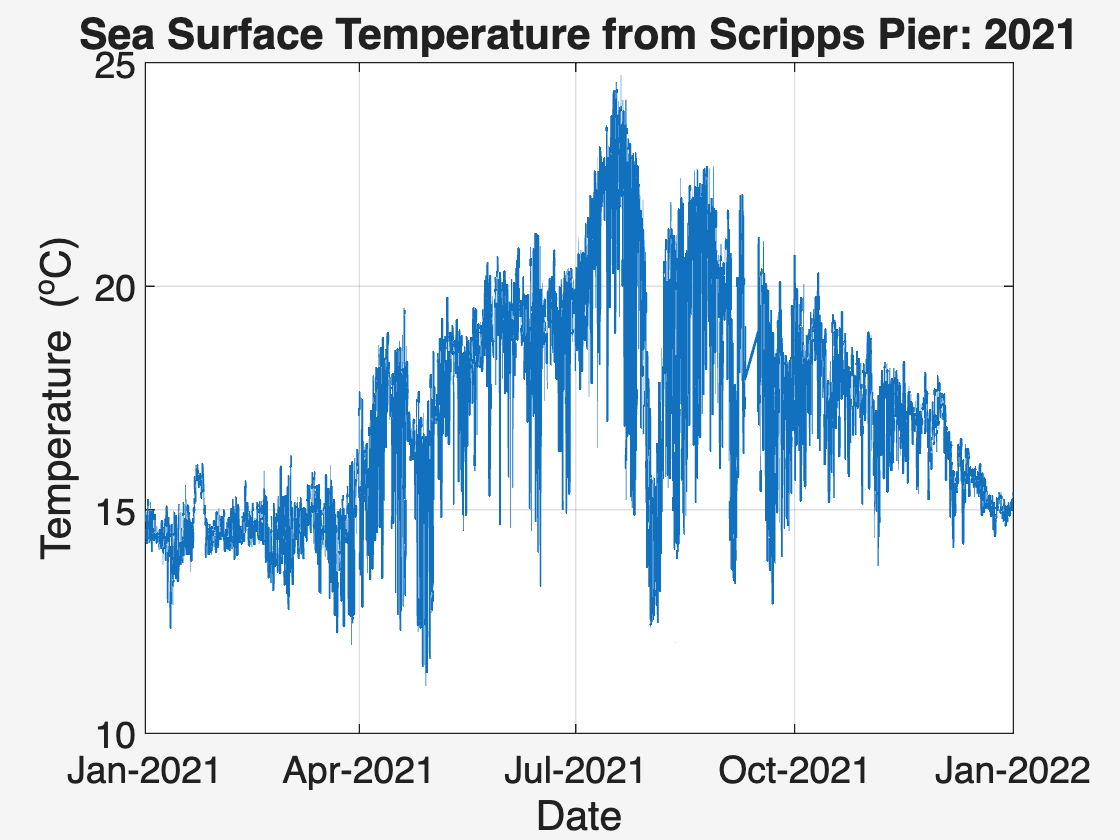

In [50]:
figure(1); clf;
plot(pier.dnum, pier.temperature, 'LineWidth', 1)
xtickformat('MMM-yyyy');
xlabel('Date')
ylabel('Temperature (^oC)')
title('Sea Surface Temperature from Scripps Pier: 2021','fontsize',16)
grid on

In [51]:
% Question 1b: Compute the mean and standard deviation for the sea surface temperature data. 

%% What do these statistics tell you about the temperature in 2021?
% These statistics tell us several things about the temperature in 2021. 
% The mean tells us the average over our time series. We can see that on average, the water temperature in 2021
% was around 17.3 °C with a standard deviation of 2.43 °C. This means that around 95% of the days had a surface temperature between 
% 12.44°C and 22.16°C. This makes sense visually while looking at the graph. We can see very few days are outside those bounds. 

In [52]:
mean_temp = mean(pier.temperature)

mean_temp = single
17.2740

In [53]:
stnd_temp = std(pier.temperature)

stnd_temp = single
2.4254

In [54]:
% Question 1c: Compute an empirical probability density function for sea surface temperature.

%% Does it look like any of the distributions that we discussed in class?
% Looking back at some of the figures from lecture 2, none of them line up perfectly. 
% However, if I were to pick what it resembles the most, I would say it looks similar to a gaussian PDF. 
% In the graph below (figure 2), we can see that temperatures about ~16°C follow the gaussian curve rather closely. 
% Where the graph differs from the expected pattern is at around 14-15°C.
% This is because there is a much higher concentration of data in that area compared to the other temperatures. 

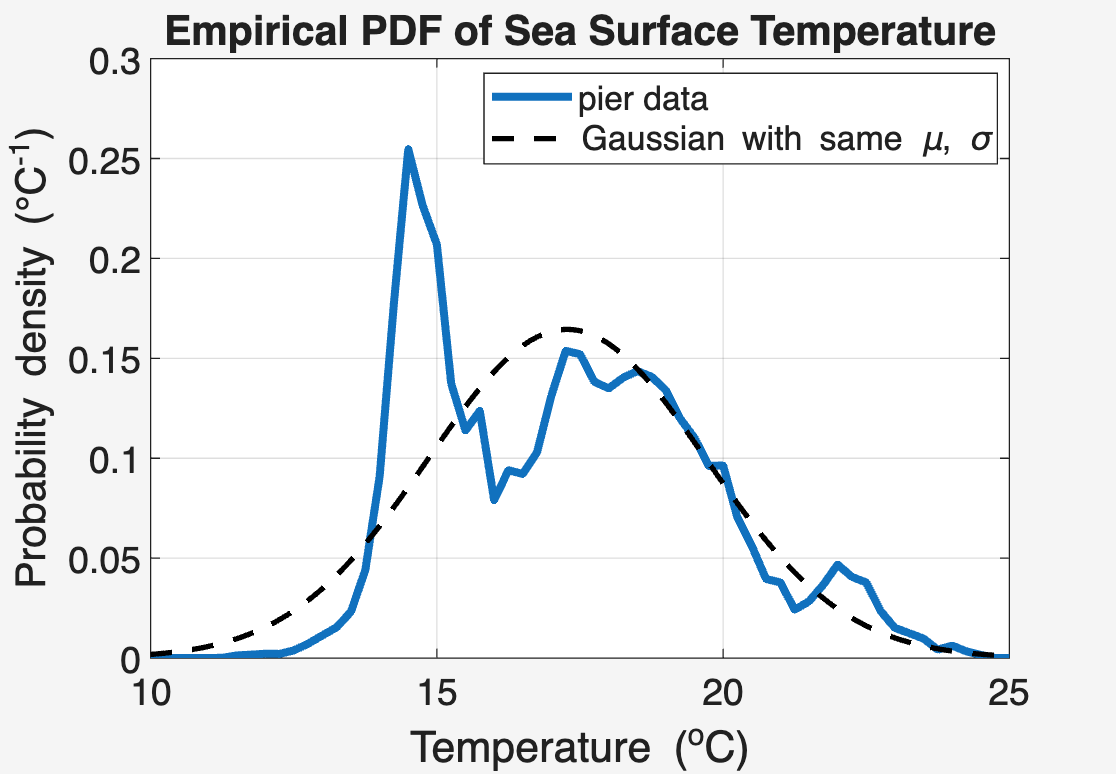

In [55]:
bin_size = 0.25;
[number_per_bin, bins] = hist(pier.temperature, 10:bin_size:25);
mu = mean_temp;
sig = stnd_temp;
x = 10:.05:25;
gauss = 1./sig./sqrt(2*pi).*exp(-(x - mu).^2./2./sig.^2);

figure(2); clf
plot(bins, number_per_bin/sum(number_per_bin)/bin_size, 'LineWidth', 3)
hold on
plot(x, gauss, 'k--', 'LineWidth', 2)
legend('pier data','Gaussian with same \mu, \sigma','Location','best')
xlabel('Temperature (^oC)','FontSize',16)
ylabel('Probability density (°C^{-1})')
title('Empirical PDF of Sea Surface Temperature')
grid on

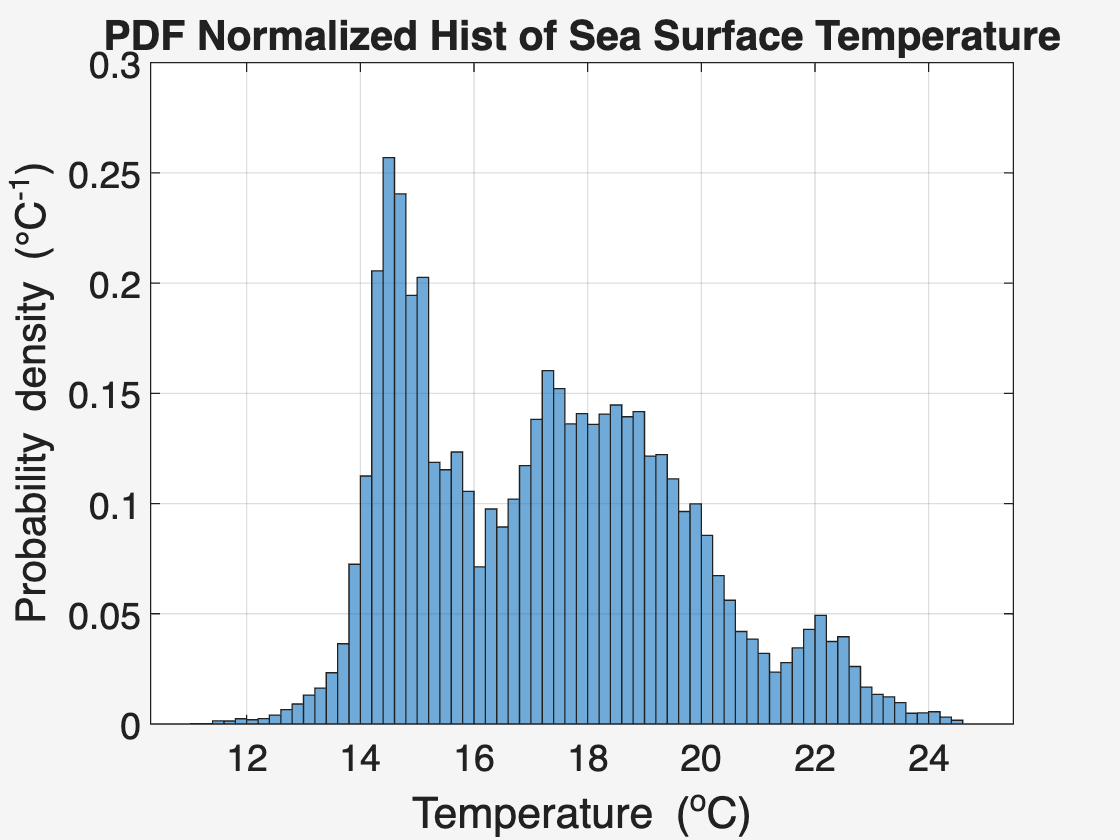

In [57]:
figure(3); clf
histogram(pier.temperature,'Normalization','pdf');
xlabel('Temperature (^oC)','FontSize',16)
ylabel('Probability density (°C^{-1})')
title('PDF Normalized Hist of Sea Surface Temperature')
grid on

In [80]:
% Question 2: Now extend your record for the temperature from 2005-2021 and repeat the calculations from 
% the first exercise using a single long timeseries stitched together using data from all years. 
% (This is a good time to practice using a loop to go through each of the data files.) 

%% What do you observe in these results?
% The first thing I noticed was an error in the data of 2005 causing there to be a 97°C data point. 
% We can comfortably assume that there was some sort of sensor/measurement error there.
% The next thing I noticed was that the data wasn't particularly varied. 
% I was expecting there to be years that were much hotter and much colder. Instead, they all stayed relatively consistent. 
% I did find it interesting that in both 2021 and the 2005-2021 PDFs, there was a slight leaning towards colder temperatures. 

%% In what ways are the 2021 results different from the 2005-2021 results? 
% The 2021 are vastly different largely due to the scope of the data.
% When looking at the 2021 data, we have n = 129244 data points. However, with 2005-2021 we have n = 1764494 data points.
% That massive increase in data means that the extrema often get smoothed out. We can see this as the 2021 PDF did not follow 
% the expected Gaussian distribution, whereas the 2005-2021 data was much closer to that same distribution. 


%% Is 2021 unusual? 
% I wouldn say that 2021 was unusual. That particular year, temperatures were strongly favorable towards colder temperatures.
% We can see this in the PDFs for 2021 and 2005-2021 witht temperatures of 14-15°C.
% In 2021, t = 14-15°C had a probability density of over 0.25. Comparing that to the PDF of 2005-2021, we can see that it has a 
% probability density of around 0.15 for the same temperature range. That shows a significant drop in temperatures for that year.

%% Is the sharp temperature change in August 2016 unusual?
% Not necessarily, the drop in temperatures in August is something that can be seen all over the temperature record each year.
% The magnitude of that particular year is unusual as there was an El Nino event occuring that increased surface temperatures. 
% The drop in temperatures during August is largely due to a combination of the California Current System and strong upwelling. 
% Upwelling in California, typically speaking, begins around June and peaks in early August.
% This is why we see surface temperatures increase after August, upwelling has calmed down and there is less cold water being pushed upward.

In [84]:
% Load all of the different years as a single continuous timeseries
%
% Function to load all .nc files for the scripps_pier data from 2005-2021.
% 
% Callouts:
%    - date0: the initial / starting date for the data. only currently good for years. 
%    - date1: the final date for the data. only currently for years. 
%    - filepath: incase you have a specific place you want to look for the data
%
% 8 Oct 2026, Ely J Dawson: created the code :)


function allpier = pierdata_allyrs(date0,date1,filepath)

    % load all available years
    if nargin < 1 || isempty(date0)
        date0 = 2005;
    end

    if nargin < 2 || isempty(date1)
        date1 = 2021;
    end

    % MATLAB's current folder
    if nargin < 3 || isempty(filepath)
        filepath = pwd;
    end

    years = date0:date1;
    n = numel(years);
    
    for k = 1:n
        filename = fullfile(filepath,sprintf('scripps_pier-%d.nc',years(k)));

        time = double(ncread(filename, 'time'));
        temp = double(ncread(filename, 'temperature'));
        pres = double(ncread(filename, 'pressure'));

        dnum = datetime(time,"ConvertFrom","posixtime");

        timeAll{k} = time(:);
        tempAll{k} = temp(:);
        presAll{k} = pres(:);
        dnumAll{k} = dnum(:);
    end

    allpier.time = vertcat(timeAll{:});
    allpier.t  = vertcat(tempAll{:});
    allpier.p = vertcat(presAll{:});
    allpier.dnum  = vertcat(dnumAll{:});

    [allpier.time, idx] = sort(allpier.time);
    allpier.t = allpier.t(idx);
    allpier.p = allpier.p(idx);
    allpier.dnum = allpier.dnum(idx);
end

allpier = pierdata_allyrs

allpier = struct with fields:
    time: [1764494×1 double]
       t: [1764494×1 double]
       p: [1764494×1 double]
    dnum: [1764494×1 datetime]

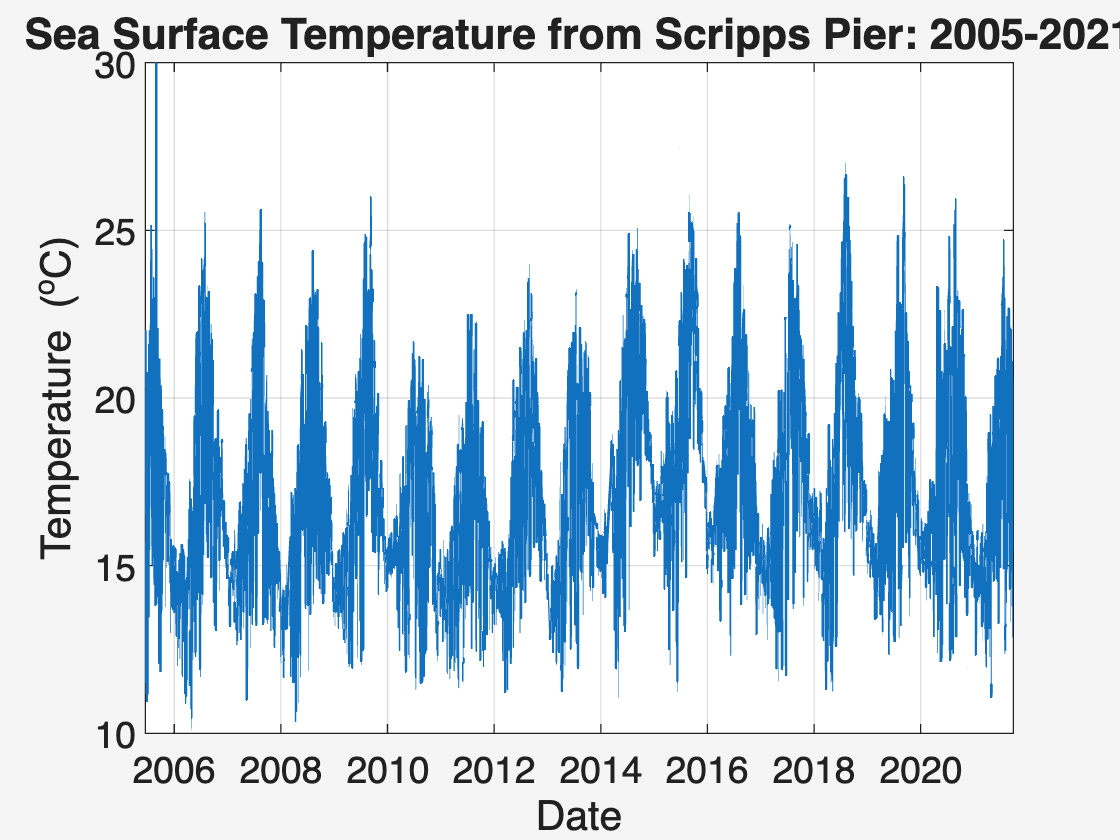

In [85]:
figure(4); clf;
plot(allpier.dnum, allpier.t, 'LineWidth', 1)
xtickformat('yyyy');
xlabel('Date')
ylabel('Temperature (^oC)')
title('Sea Surface Temperature from Scripps Pier: 2005-2021','fontsize',16)
ylim([10 30])
grid on

In [86]:
mu = mean(allpier.t)

mu = 17.8145

In [87]:
sig = std(allpier.t)

sig = 2.7583

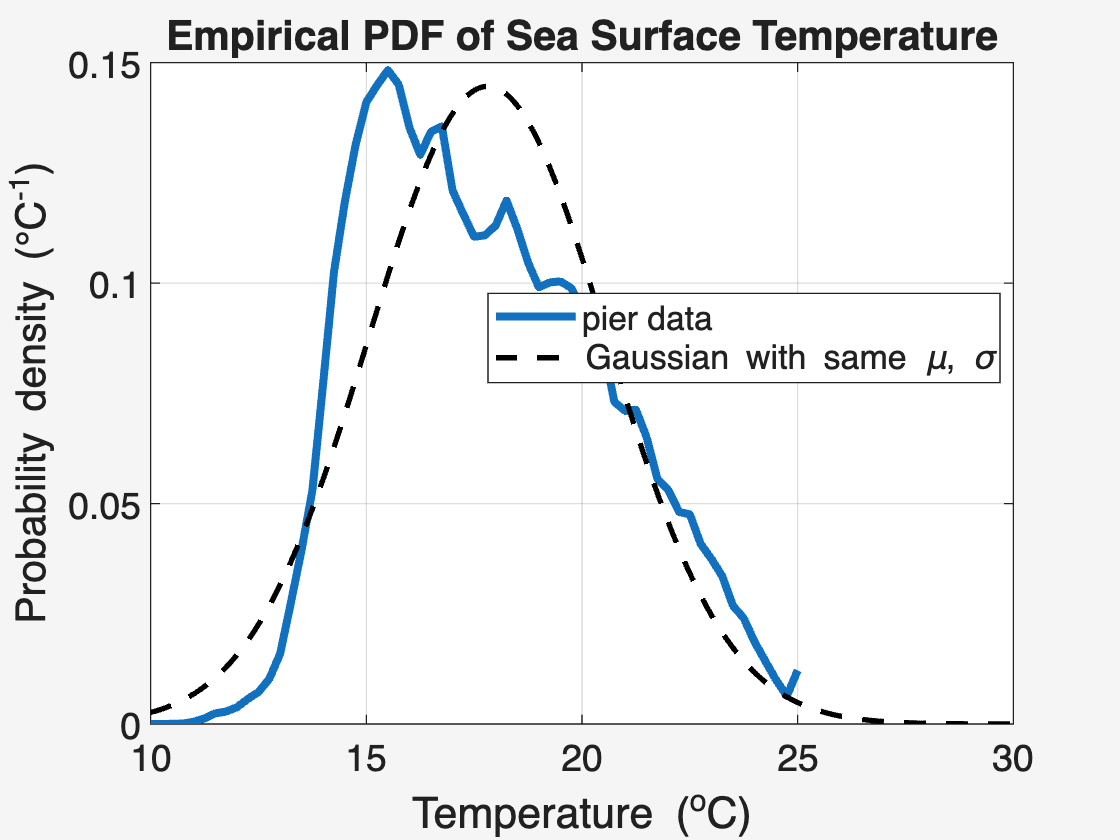

In [88]:
bin_size = 0.25;
[number_per_bin, bins] = hist(allpier.t, 10:bin_size:25);
x = 10:.05:30;
gauss = 1./sig./sqrt(2*pi).*exp(-(x - mu).^2./2./sig.^2);

figure(5); clf
plot(bins, number_per_bin/sum(number_per_bin)/bin_size, 'LineWidth', 3)
hold on
plot(x, gauss, 'k--', 'LineWidth', 2)
legend('pier data','Gaussian with same \mu, \sigma','Location','best')
xlabel('Temperature (^oC)','FontSize',16)
ylabel('Probability density (°C^{-1})')
title('Empirical PDF of Sea Surface Temperature')
grid on

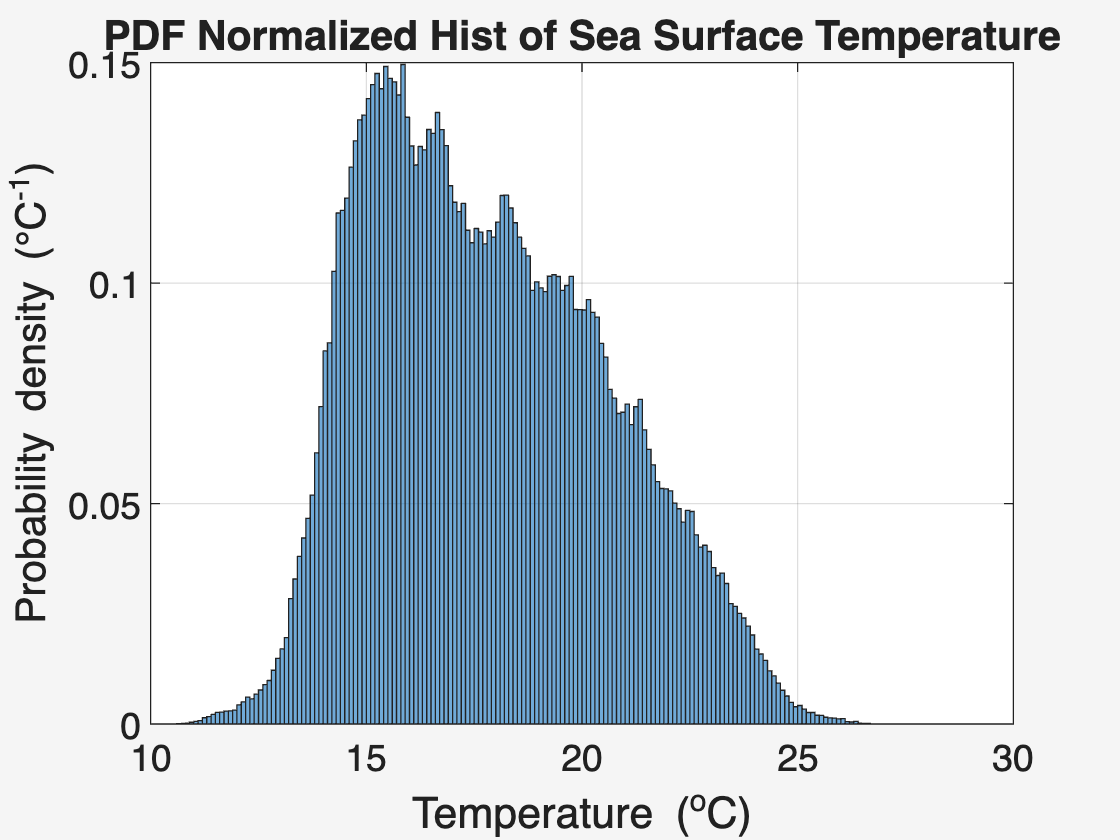

In [89]:
figure(6); clf
histogram(allpier.t,'Normalization','pdf');
xlabel('Temperature (^oC)','FontSize',16)
ylabel('Probability density (°C^{-1})')
title('PDF Normalized Hist of Sea Surface Temperature')
xlim([10 30])
grid on

In [90]:
idx = year(allpier.dnum) == 2016;
pier2016.dnum = allpier.dnum(idx);
pier2016.time = allpier.time(idx);
pier2016.t    = allpier.t(idx);
pier2016.p    = allpier.p(idx);

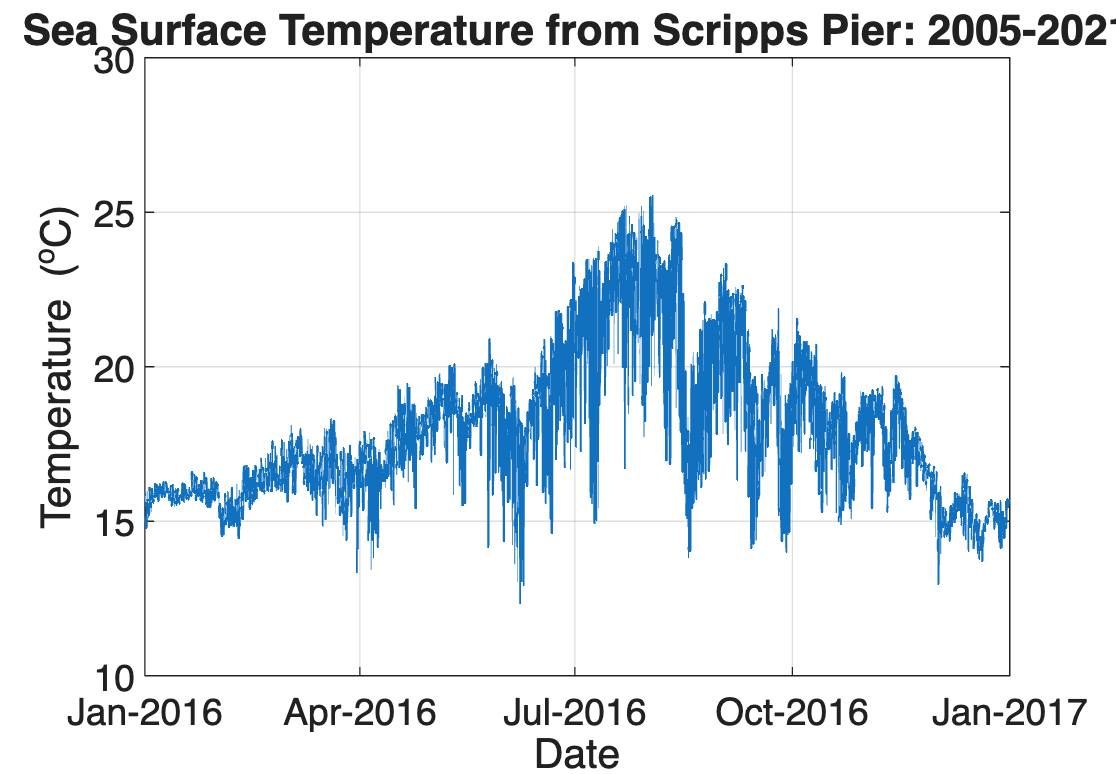

In [91]:
figure(7); clf;
plot(pier2016.dnum, pier2016.t, 'LineWidth', 1)
xtickformat('MMM-yyyy');
xlabel('Date')
ylabel('Temperature (^oC)')
title('Sea Surface Temperature from Scripps Pier: 2005-2021','fontsize',16)
ylim([10 30])
grid on